# Session 11 – code from the session notes
One code cell per code screenshot in the Session 11 notes; the page numbers refer to the notes. The data from Brooks, Examples 11.1–11.3, are typed in directly, so no data files are needed. Run the cells from the top: later cells use `table`, `O`, `chi2_stat` and `rng` from earlier cells.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats

rng = np.random.default_rng(2026)

## Page 5 – goodness of fit, specified probabilities (Example 11.1)

In [2]:
observed = np.array([212, 96, 58, 34])          # alignment, contamination, solder, other
p0 = np.array([0.45, 0.30, 0.15, 0.10])
expected = observed.sum() * p0

gof = stats.chisquare(observed, f_exp=expected)
print("expected:", expected)
print(f"chi2 = {gof.statistic:.3f}, df = {len(observed) - 1}, p = {gof.pvalue:.4f}")

expected: [180. 120.  60.  40.]
chi2 = 11.456, df = 3, p = 0.0095


## Page 8 – Poisson goodness of fit, one fitted parameter (Example 11.2)

In [3]:
observed = np.array([11, 17, 36, 38, 42, 27, 17, 12])   # 0, 1, ..., 6, 7+ alerts
rate = 3.49                                               # estimated from the raw data

k = np.arange(7)
probs = np.append(stats.poisson.pmf(k, mu=rate), stats.poisson.sf(6, mu=rate))  # last: P(X >= 7)
expected = observed.sum() * probs

gof = stats.chisquare(observed, f_exp=expected, ddof=1)   # df = k - 1 - 1
print("expected:", expected.round(2))
print(f"chi2 = {gof.statistic:.3f}, df = {len(observed) - 1 - 1}, p = {gof.pvalue:.3f}")

expected: [ 6.1  21.29 37.15 43.22 37.71 26.32 15.31 12.9 ]
chi2 = 6.222, df = 6, p = 0.399


## Page 14 – contingency table: test, expected counts, residuals, Cramér's V (Example 11.3)

In [4]:
table = pd.DataFrame([[25, 40, 15, 40], [40, 25, 15, 40], [55, 10, 10, 45]],
                     index=["L1", "L2", "L3"],
                     columns=["alignment", "contamination", "solder", "other"])

chi2_stat, p_val, dof, expected = stats.chi2_contingency(table, correction=False)
print(f"chi2 = {chi2_stat:.2f}, df = {dof}, p = {p_val:.2g}, min E = {expected.min():.2f}")

O, N = table.to_numpy(), table.to_numpy().sum()
print("row shares:\n", table.div(table.sum(axis=1), axis=0).round(3))

pearson = (O - expected) / np.sqrt(expected)
print("Pearson residuals:\n", pd.DataFrame(pearson, index=table.index, columns=table.columns).round(2))

p_row = O.sum(axis=1, keepdims=True) / N
p_col = O.sum(axis=0, keepdims=True) / N
adj = (O - expected) / np.sqrt(expected * (1 - p_row) * (1 - p_col))
print("adjusted residuals:\n", pd.DataFrame(adj, index=table.index, columns=table.columns).round(2))

V = np.sqrt(chi2_stat / (N * min(O.shape[0] - 1, O.shape[1] - 1)))
print(f"Cramér's V = {V:.3f}")

chi2 = 30.90, df = 6, p = 2.6e-05, min E = 13.33
row shares:
     alignment  contamination  solder  other
L1      0.208          0.333   0.125  0.333
L2      0.333          0.208   0.125  0.333
L3      0.458          0.083   0.083  0.375
Pearson residuals:
     alignment  contamination  solder  other
L1      -2.37            3.0    0.46  -0.26
L2       0.00            0.0    0.46  -0.26
L3       2.37           -3.0   -0.91   0.52
adjusted residuals:
     alignment  contamination  solder  other
L1      -3.56           4.13    0.59  -0.39
L2       0.00           0.00    0.59  -0.39
L3       3.56          -4.13   -1.19   0.78
Cramér's V = 0.207


### Alternative: the same analysis with statsmodels
Not in the notes. `sm.stats.Table` gives the expected counts, test, Pearson residuals and adjusted residuals (statsmodels calls them `standardized_resids`) directly.

expected counts:
     alignment  contamination  solder  other
L1       40.0           25.0   13.33  41.67
L2       40.0           25.0   13.33  41.67
L3       40.0           25.0   13.33  41.67
minimum expected count: 13.33
chi2 = 30.90, df = 6, p = 2.649e-05
Pearson residuals:
     alignment  contamination  solder  other
L1      -2.37            3.0    0.46  -0.26
L2       0.00            0.0    0.46  -0.26
L3       2.37           -3.0   -0.91   0.52
adjusted residuals:
     alignment  contamination  solder  other
L1      -3.56           4.13    0.59  -0.39
L2       0.00           0.00    0.59  -0.39
L3       3.56          -4.13   -1.19   0.78
contributions to chi2:
     alignment  contamination  solder  other
L1       5.62            9.0    0.21   0.07
L2       0.00            0.0    0.21   0.07
L3       5.62            9.0    0.83   0.27
Cramér's V = 0.207


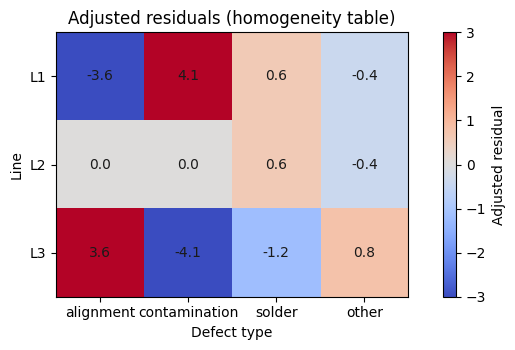

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import contingency

# Same homogeneity table as in the previous cell (`table`, rows = lines, columns = defect types)
order = list(table.columns)

# One object holds the table and everything computed from it
ct = sm.stats.Table(table)

# Expected counts and the E >= 5 check
print("expected counts:\n", ct.fittedvalues.round(2))
print("minimum expected count:", round(ct.fittedvalues.to_numpy().min(), 2))

# Pearson chi-square test (no Yates correction)
res = ct.test_nominal_association()
print(f"chi2 = {res.statistic:.2f}, df = {res.df}, p = {res.pvalue:.4g}")

# Residuals: Pearson, adjusted (statsmodels calls them standardized), contributions
print("Pearson residuals:\n", ct.resid_pearson.round(2))
print("adjusted residuals:\n", ct.standardized_resids.round(2))
print("contributions to chi2:\n", ct.chi2_contribs.round(2))

# Cramér's V
V = contingency.association(table, method="cramer")
print(f"Cramér's V = {V:.3f}")

# Heatmap of the adjusted residuals
adj = ct.standardized_resids
fig, ax = plt.subplots(figsize=(7.2, 3.6))
im = ax.imshow(adj, cmap="coolwarm", vmin=-3, vmax=3)
ax.set_xticks(range(len(order)), order)
ax.set_yticks(range(len(table.index)), table.index)
ax.set_xlabel("Defect type")
ax.set_ylabel("Line")
ax.set_title("Adjusted residuals (homogeneity table)")
for i in range(adj.shape[0]):
    for j in range(adj.shape[1]):
        ax.text(j, i, f"{adj.iloc[i, j]:.1f}", ha="center", va="center", color="0.1")
fig.colorbar(im, ax=ax, label="Adjusted residual")
plt.tight_layout()
plt.show()

## Page 16 – Monte Carlo: shuffle the line labels

In [6]:
lines = np.repeat(table.index, O.sum(axis=1))                 # one label per defect record
types = np.concatenate([np.repeat(table.columns, r) for r in O])

B = 5000
sim = np.empty(B)
for b in range(B):
    shuffled = pd.crosstab(rng.permutation(lines), types)
    sim[b] = stats.chi2_contingency(shuffled, correction=False)[0]

p_mc = (1 + np.sum(sim >= chi2_stat)) / (B + 1)
print(f"largest simulated chi2 = {sim.max():.2f}, Monte Carlo p = {p_mc:.4f}")

largest simulated chi2 = 25.18, Monte Carlo p = 0.0002


## Page 16 – Fisher's exact test (pilot test)

In [7]:
table = pd.DataFrame([[1, 11], [6, 6]], index=["supplier A", "supplier B"], columns=["fail", "pass"])

chi2_stat, p_chi2, dof, expected = stats.chi2_contingency(table, correction=False)
print("expected:\n", expected.round(2))
print(f"chi2 curve: chi2 = {chi2_stat:.2f}, p = {p_chi2:.3f}")

odds_ratio, p_fisher = stats.fisher_exact(table)
print(f"Fisher: odds ratio = {odds_ratio:.3f}, p = {p_fisher:.3f}")

expected:
 [[3.5 8.5]
 [3.5 8.5]]
chi2 curve: chi2 = 5.04, p = 0.025
Fisher: odds ratio = 0.091, p = 0.069
